In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
atm_2d

NameError: name 'test_projections' is not defined

In [2]:
agg_np =xr.open_dataset("/wolke_scratch/dnikolo/Glaciation_time_estimator/grids/agg_pixel_area_np.nc", decode_times=False)
non_agg_np =xr.open_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc", decode_times=False)


In [4]:
lats = agg_np.lat.isel(georef_offset_corrected=0).values
pix_area = agg_np.pixel_area.isel(georef_offset_corrected=0).values
pix_area_non_agg = non_agg_np.pixel_area.isel(georef_offset_corrected=0).values

In [5]:
np.count_nonzero(pix_area[(lats>0)& (lats<20)]==0)

112

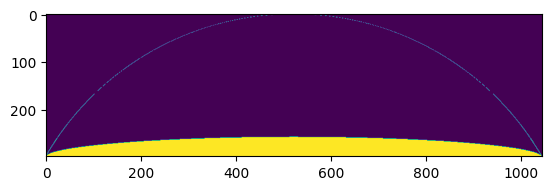

In [6]:
plt.imshow((lats>0)& (lats<30))

In [7]:
conic = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/aux_tools/out_conic.nc")
curvilinear = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/aux_tools/out_curvilinear.nc")
mercador = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/Nudged_run_cph_05_03/resample_test/remap_laf_whole_ryan_nudged_test_v0203_ctp_2d_ml_20080901T000000Z.nc")

In [8]:
satellite = xr.open_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2007/09/01/CTXin20070901001500405SVMSG01MD.nc")

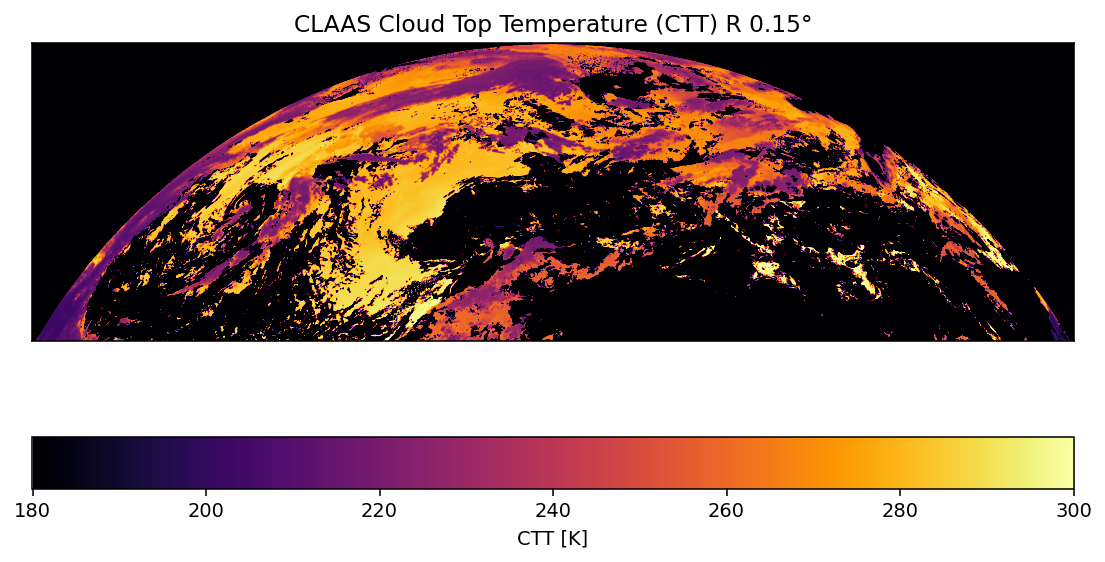

In [9]:
sat_ctt = satellite.ctt.isel(time=0).values
sat_ctt[np.isnan(sat_ctt)] = 0

fig, ax = plt.subplots(figsize=(8, 5), dpi=140)
im = ax.imshow(sat_ctt, vmin=180, vmax=300, cmap="inferno")
ax.set_xticks([])
ax.set_yticks([])
cb = fig.colorbar(im, ax=ax, orientation="horizontal",label="CTT [K]")
ax.set_title("CLAAS Cloud Top Temperature (CTT) R 0.15°")
plt.tight_layout()
plt.show()

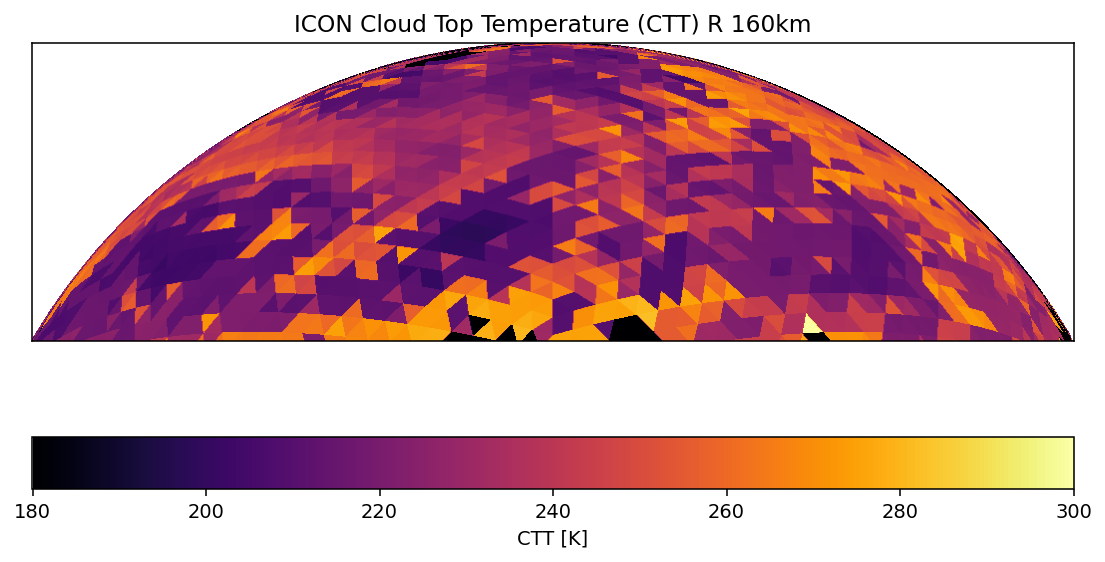

In [15]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=140)
im = ax.imshow(curvilinear.ctt.isel(time=1), vmin=180, vmax=300,cmap="inferno")
ax.set_xticks([])
ax.set_yticks([])
cb = fig.colorbar(im, ax=ax, orientation="horizontal",label="CTT [K]")
ax.set_title("ICON Cloud Top Temperature (CTT) R 160km")
plt.tight_layout()
plt.show()

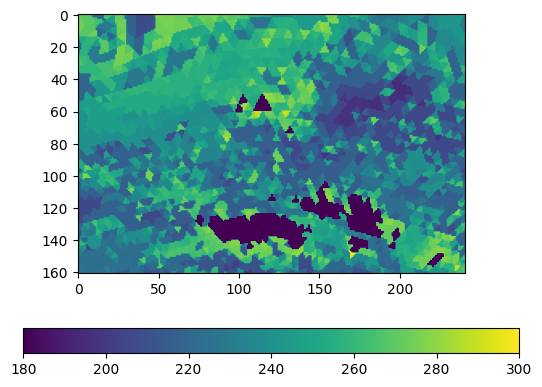

In [11]:
plt.imshow(conic.ctt.isel(time=1),vmin=180, vmax=300)
plt.colorbar(orientation="horizontal")

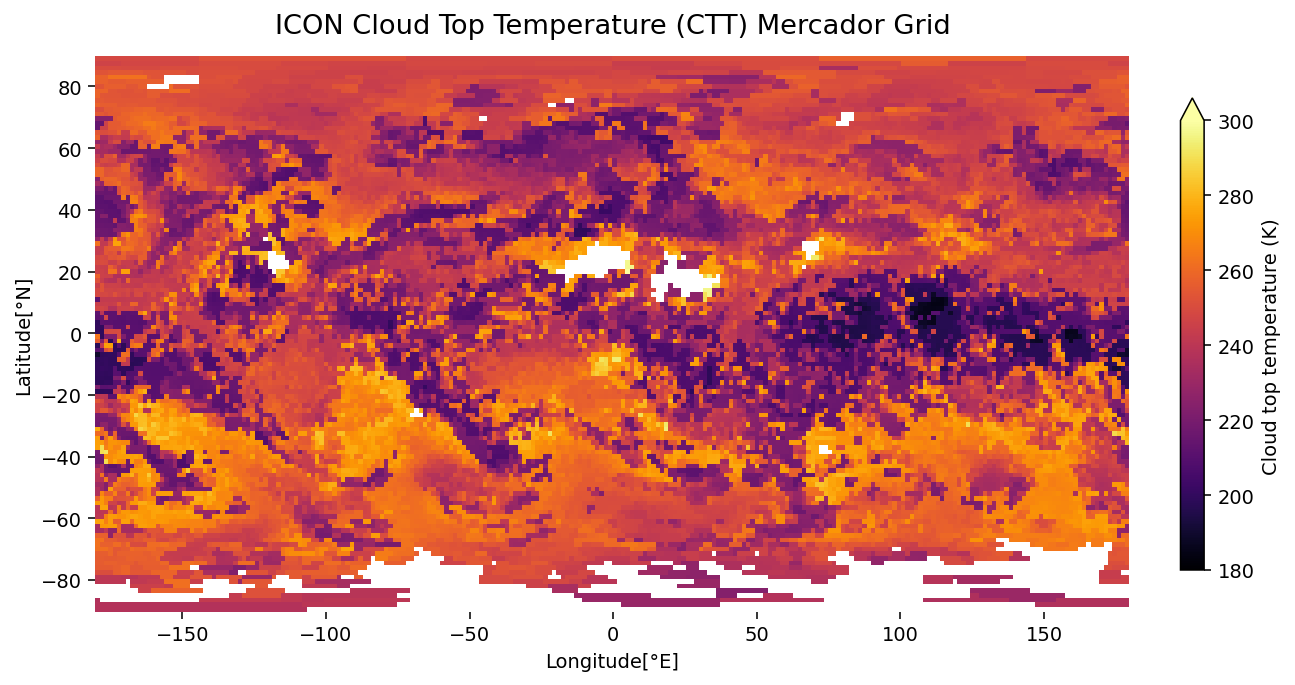

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5), dpi=140)

mercador.ctt.isel(time=1).plot(
    ax=ax,
    cmap="inferno",
    vmin=180,
    vmax=300,
    cbar_kwargs={
        "label": "Cloud top temperature (K)",
        "shrink": 0.85,
        "pad": 0.04
    }
)

ax.set_title("ICON Cloud Top Temperature (CTT) Mercador Grid", fontsize=14, pad=12)
ax.set_xlabel("Longitude[°E]")
ax.set_ylabel("Latitude[°N]")
# ax.set_xticks([])
# ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

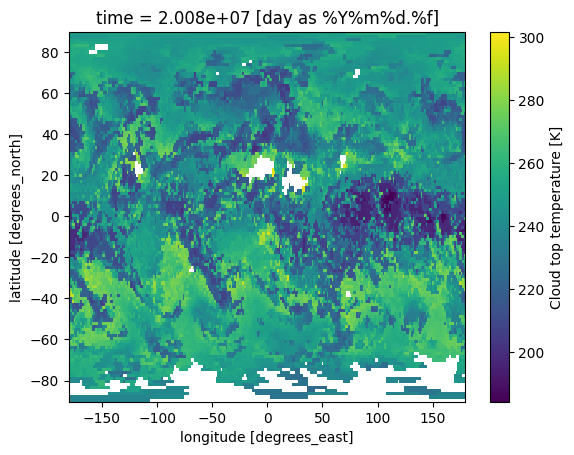

In [13]:
mercador.ctt.isel(time=1).plot()

In [3]:
ts = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/nudged_3m/test.nc")


In [4]:
ts.tas

<xarray.DataArray 'tas' (time: 96, height_2: 1, y: 299, x: 1045)>
[29995680 values with dtype=float64]
Coordinates:
  * time      (time) float64 2.008e+07 2.008e+07 ... 2.008e+07 2.008e+07
    lon       (y, x) float64 ...
    lat       (y, x) float64 ...
  * height_2  (height_2) float64 2.0
Dimensions without coordinates: y, x
Attributes:
    standard_name:  tas
    long_name:      temperature in 2m
    units:          K
    param:          0.0.0

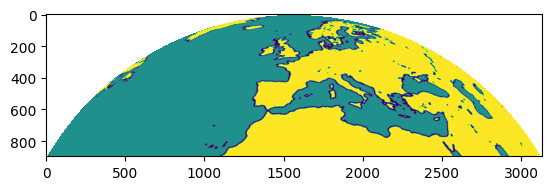

In [5]:
plt.imshow(non_agg_np.lsm.isel(georef_offset_corrected=0).values)

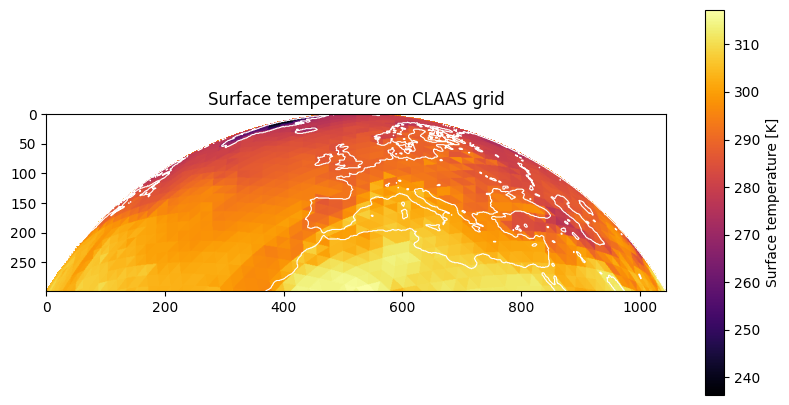

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# --- arrays ---
lsm = non_agg_np.lsm.isel(georef_offset_corrected=0).values
tas2d = ts.tas.isel(time=1).values[0, :, :]

# --- resize mask to tas shape ---
zoom_y = tas2d.shape[0] / lsm.shape[0]
zoom_x = tas2d.shape[1] / lsm.shape[1]
lsm_resized = zoom(lsm, (zoom_y, zoom_x), order=0)  # nearest-neighbor for categorical mask

# crop in case of 1-pixel mismatch
ny = min(tas2d.shape[0], lsm_resized.shape[0])
nx = min(tas2d.shape[1], lsm_resized.shape[1])

tas_plot = tas2d[:ny, :nx]
lsm_plot = lsm_resized[:ny, :nx]

# --- define land mask correctly ---
land_mask = (lsm_plot == 3).astype(float)

# --- plot ---
plt.figure(figsize=(10, 5))
im = plt.imshow(tas_plot, cmap="inferno", origin="upper")
plt.contour(land_mask, levels=[0.5], colors="white", linewidths=0.8)
plt.colorbar(im, label="Surface temperature [K]")
plt.title("Surface temperature on CLAAS grid")
plt.show()

/wolke_scratch/dnikolo/conda_envs/msgi_env/lib/python3.11/site-packages/matplotlib/colorbar.py:1229: RuntimeWarning: invalid value encountered in divide
  y = y / (self._boundaries[self._inside][-1] -


IndexError: index 1 is out of bounds for axis 0 with size 1

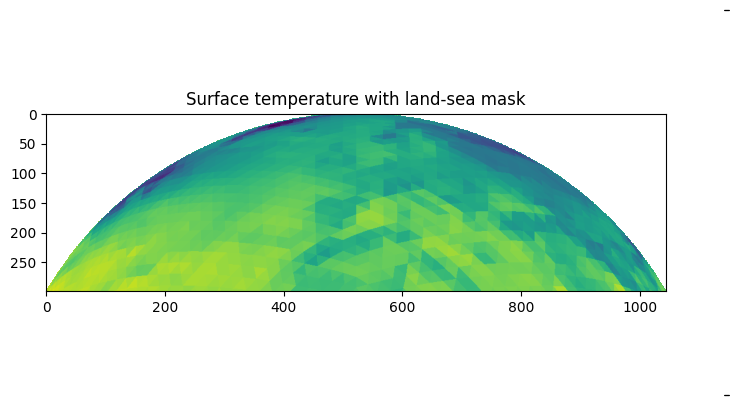

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# --- get arrays ---
lsm_hi = non_agg_np.lsm.isel(georef_offset_corrected=0).values   # high-res land/sea mask
tas2d  = ts.tas.isel(time=10).values[0, :, :]                    # surface temperature

# --- resize mask to tas shape ---
# nearest-neighbor is best for categorical masks
zoom_factors = (
    tas2d.shape[0] / lsm_hi.shape[0],
    tas2d.shape[1] / lsm_hi.shape[1]
)
lsm_on_tas = zoom(lsm_hi, zoom_factors, order=0)

# --- plot ---
plt.figure(figsize=(10, 5))
plt.imshow(tas2d, origin="upper")
plt.contour(lsm_on_tas, levels=[0.5], colors="red", linewidths=1.0)
plt.title("Surface temperature with land-sea mask")
plt.colorbar(label="tas")
plt.show()

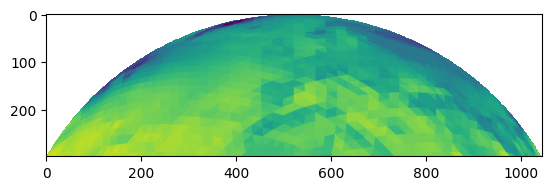

In [ ]:
plt.imshow(ts.tas.isel(time=10).values[0,:,:])